In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd

train = pd.read_csv(
    "../dataset/raw/train_FD001.txt",
    sep=r"\s+",
    header=None
)

print(train.head())
print(train.shape)

   0   1       2       3      4       5       6        7        8      9   \
0   1   1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60  14.62   
1   1   2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14  14.62   
2   1   3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20  14.62   
3   1   4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87  14.62   
4   1   5 -0.0019 -0.0002  100.0  518.67  642.37  1582.85  1406.22  14.62   

   ...      16       17       18      19    20   21    22     23     24  \
0  ...  521.66  2388.02  8138.62  8.4195  0.03  392  2388  100.0  39.06   
1  ...  522.28  2388.07  8131.49  8.4318  0.03  392  2388  100.0  39.00   
2  ...  522.42  2388.03  8133.23  8.4178  0.03  390  2388  100.0  38.95   
3  ...  522.86  2388.08  8133.83  8.3682  0.03  392  2388  100.0  38.88   
4  ...  522.19  2388.04  8133.80  8.4294  0.03  393  2388  100.0  38.90   

        25  
0  23.4190  
1  23.4236  
2  23.3442  
3  23.3739  
4  23.4044  

[5 rows

In [4]:
test = pd.read_csv(
    "../dataset/raw/test_FD001.txt",
    sep=r"\s+",
    header=None
)

rul = pd.read_csv(
    "../dataset/raw/RUL_FD001.txt",
    sep=r"\s+",
    header=None
)

print("Testing shape:", test.shape)
print("RUL shape:", rul.shape)

Testing shape: (13096, 26)
RUL shape: (100, 1)


In [5]:
columns = [
    "Engine_ID",
    "Cycle",
    "Setting_1",
    "Setting_2",
    "Setting_3"
]

for i in range(1, 22):
    columns.append("Sensor_" + str(i))

train.columns = columns
test.columns = columns
rul.columns = ["RUL"]

print(train.head())

   Engine_ID  Cycle  Setting_1  Setting_2  Setting_3  Sensor_1  Sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   Sensor_3  Sensor_4  Sensor_5  ...  Sensor_12  Sensor_13  Sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   Sensor_15  Sensor_16  Sensor_17  Sensor_18  Sensor_19  Sensor_20  Sensor_21  
0     8.4195       0.03

In [6]:
rul.columns

Index(['RUL'], dtype='str')

In [7]:
print("Dataset information:")
train.info()

print("\nStatistical summary:")
print(train.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Engine_ID  20631 non-null  int64  
 1   Cycle      20631 non-null  int64  
 2   Setting_1  20631 non-null  float64
 3   Setting_2  20631 non-null  float64
 4   Setting_3  20631 non-null  float64
 5   Sensor_1   20631 non-null  float64
 6   Sensor_2   20631 non-null  float64
 7   Sensor_3   20631 non-null  float64
 8   Sensor_4   20631 non-null  float64
 9   Sensor_5   20631 non-null  float64
 10  Sensor_6   20631 non-null  float64
 11  Sensor_7   20631 non-null  float64
 12  Sensor_8   20631 non-null  float64
 13  Sensor_9   20631 non-null  float64
 14  Sensor_10  20631 non-null  float64
 15  Sensor_11  20631 non-null  float64
 16  Sensor_12  20631 non-null  float64
 17  Sensor_13  20631 non-null  float64
 18  Sensor_14  20631 non-null  float64
 19  Sensor_15  20631 non-null  float64
 

In [8]:
print("Missing values:")
print(train.isnull().sum().sum())

print("Duplicate records:")
print(train.duplicated().sum())

Missing values:
0
Duplicate records:
0


In [9]:
print("Total engines:", train["Engine_ID"].nunique())

print("Total operating cycles:", train["Cycle"].max())

Total engines: 100
Total operating cycles: 362



RUL = Maximum Engine Cycle - Current Cycle

In [10]:
# Find the maximum cycle of each engine
max_cycles = train.groupby("Engine_ID")["Cycle"].max()

# Calculate RUL
train["RUL"] = train["Engine_ID"].map(max_cycles) - train["Cycle"]

# Display results
print(train[["Engine_ID", "Cycle", "RUL"]].head(10))

   Engine_ID  Cycle  RUL
0          1      1  191
1          1      2  190
2          1      3  189
3          1      4  188
4          1      5  187
5          1      6  186
6          1      7  185
7          1      8  184
8          1      9  183
9          1     10  182


In [11]:
print(train[["Engine_ID", "Cycle", "RUL"]].tail(10))

       Engine_ID  Cycle  RUL
20621        100    191    9
20622        100    192    8
20623        100    193    7
20624        100    194    6
20625        100    195    5
20626        100    196    4
20627        100    197    3
20628        100    198    2
20629        100    199    1
20630        100    200    0


In [12]:
print(train["RUL"].describe())

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


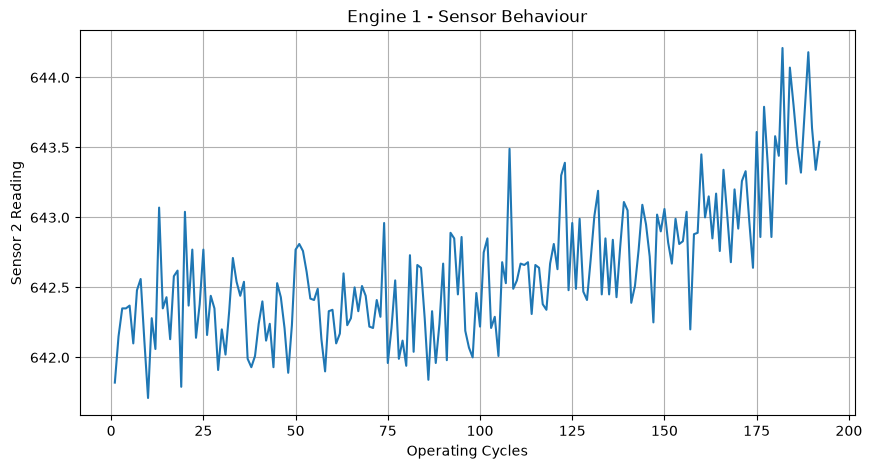

In [13]:
import matplotlib.pyplot as plt

engine_1 = train[train["Engine_ID"] == 1]

plt.figure(figsize=(10, 5))

plt.plot(
    engine_1["Cycle"],
    engine_1["Sensor_2"]
)

plt.xlabel("Operating Cycles")
plt.ylabel("Sensor 2 Reading")
plt.title("Engine 1 - Sensor Behaviour")

plt.grid(True)
plt.show()

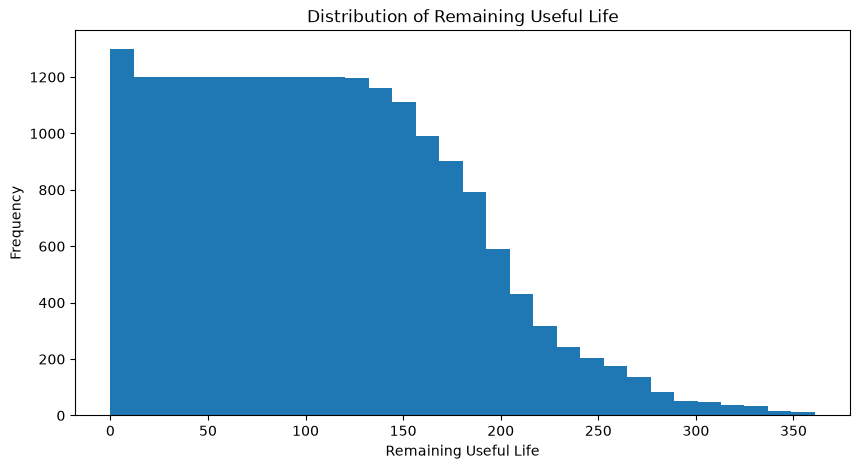

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(train["RUL"], bins=30)

plt.xlabel("Remaining Useful Life")
plt.ylabel("Frequency")
plt.title("Distribution of Remaining Useful Life")

plt.show()

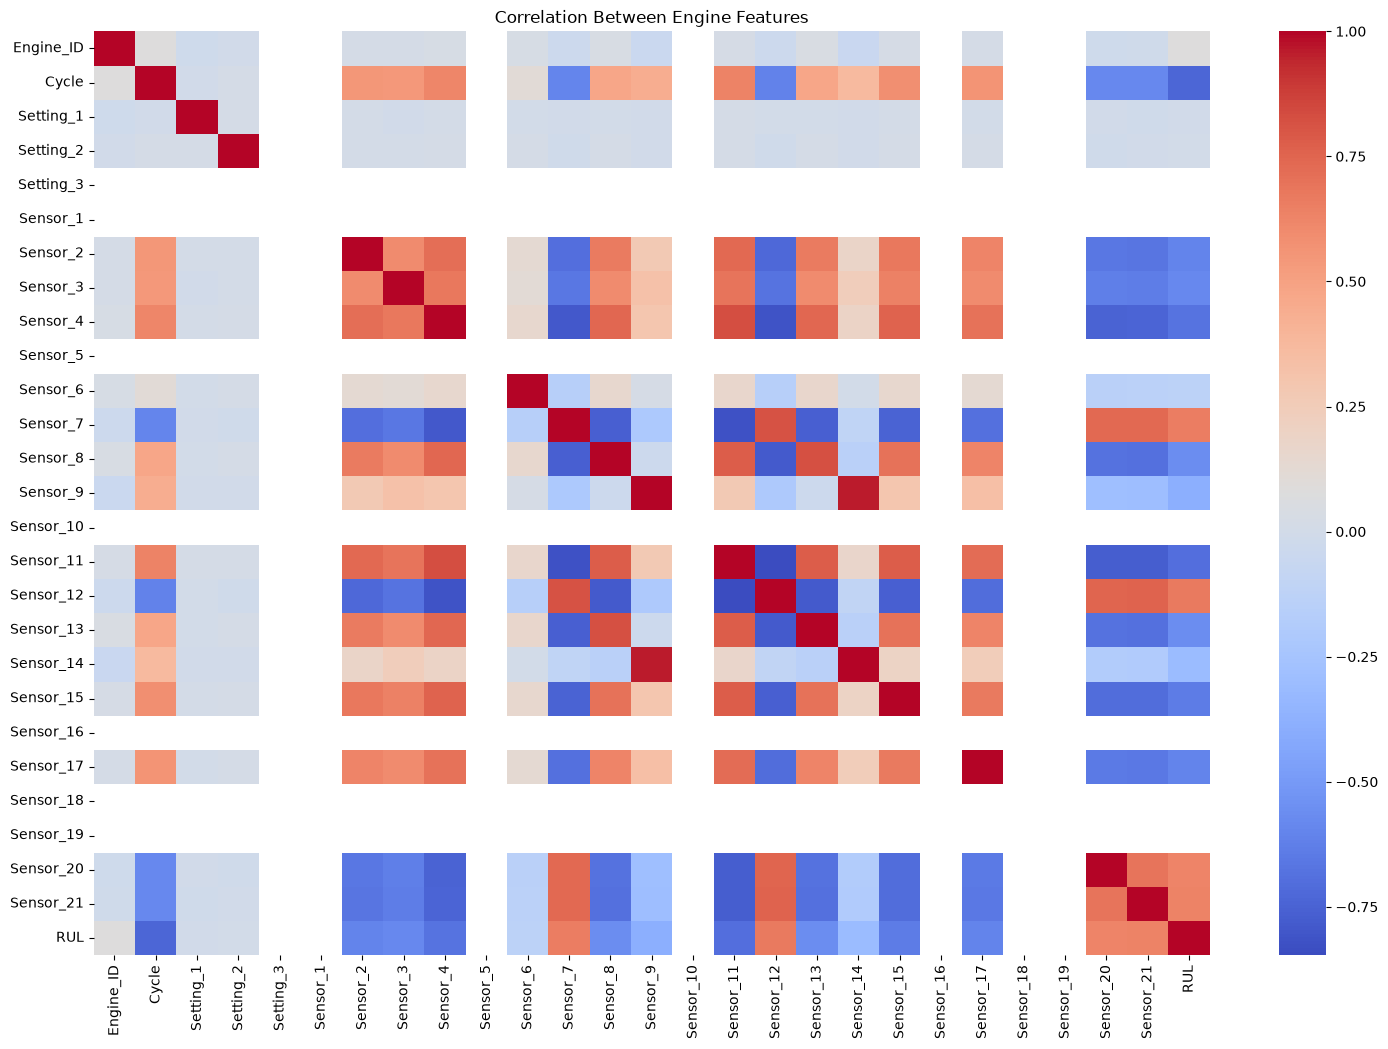

In [15]:
import seaborn as sns

correlation = train.corr(numeric_only=True)

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Between Engine Features")

plt.show()

In [16]:
# Calculate standard deviation of all sensors

sensor_columns = []

for i in range(1, 22):
    sensor_columns.append("Sensor_" + str(i))

sensor_std = train[sensor_columns].std()

print(sensor_std.sort_values())

Sensor_1     0.000000e+00
Sensor_10    0.000000e+00
Sensor_19    0.000000e+00
Sensor_18    0.000000e+00
Sensor_16    3.469531e-18
Sensor_5     5.329200e-15
Sensor_6     1.388985e-03
Sensor_15    3.750504e-02
Sensor_8     7.098548e-02
Sensor_13    7.191892e-02
Sensor_21    1.082509e-01
Sensor_20    1.807464e-01
Sensor_11    2.670874e-01
Sensor_2     5.000533e-01
Sensor_12    7.375534e-01
Sensor_7     8.850923e-01
Sensor_17    1.548763e+00
Sensor_3     6.131150e+00
Sensor_4     9.000605e+00
Sensor_14    1.907618e+01
Sensor_9     2.208288e+01
dtype: float64


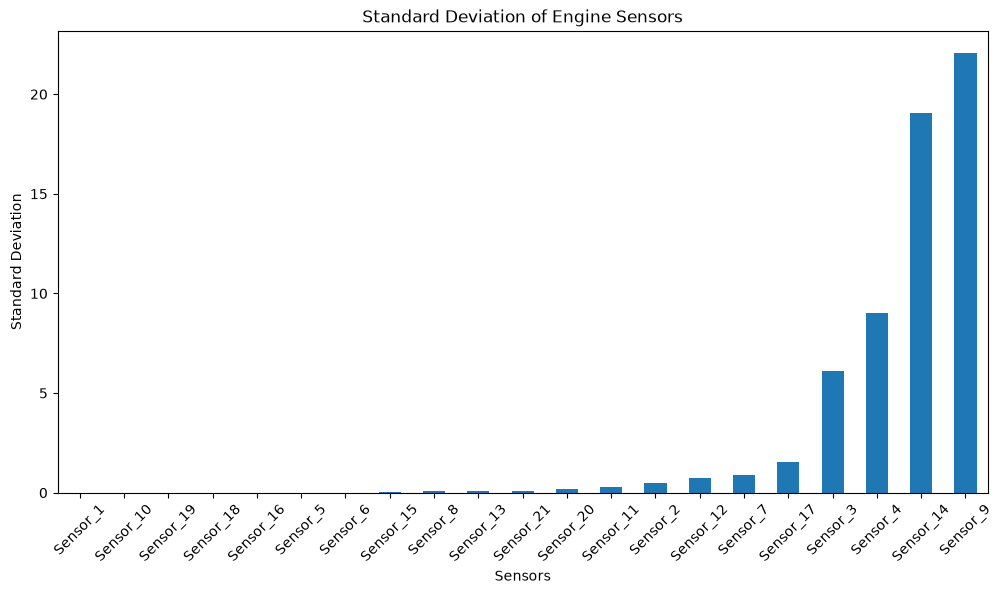

In [17]:
plt.figure(figsize=(12, 6))

sensor_std.sort_values().plot(kind="bar")

plt.title("Standard Deviation of Engine Sensors")
plt.xlabel("Sensors")
plt.ylabel("Standard Deviation")

plt.xticks(rotation=45)
plt.show()


In [18]:
selected_sensors = sensor_std[sensor_std > 0.01].index.tolist()

print("Total sensors:", len(sensor_columns))
print("Selected sensors:", len(selected_sensors))

print(selected_sensors)

Total sensors: 21
Selected sensors: 14
['Sensor_2', 'Sensor_3', 'Sensor_4', 'Sensor_7', 'Sensor_8', 'Sensor_9', 'Sensor_11', 'Sensor_12', 'Sensor_13', 'Sensor_14', 'Sensor_15', 'Sensor_17', 'Sensor_20', 'Sensor_21']


In [19]:
feature_columns = [
    "Cycle",
    "Setting_1",
    "Setting_2",
    "Setting_3"
] + selected_sensors

X = train[feature_columns]

y = train["RUL"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (20631, 18)
Target: (20631,)


In [20]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_index, val_index = next(
    splitter.split(X, y, groups=train["Engine_ID"])
)

X_train = X.iloc[train_index]
X_val = X.iloc[val_index]

y_train = y.iloc[train_index]
y_val = y.iloc[val_index]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (16561, 18)
Validation data: (4070, 18)


In [21]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predictions = model.predict(X_val)

mae = mean_absolute_error(y_val, predictions)

rmse = np.sqrt(mean_squared_error(y_val, predictions))

r2 = r2_score(y_val, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 24.045
RMSE: 31.748280144948986
R2 Score: 0.7661454987806342


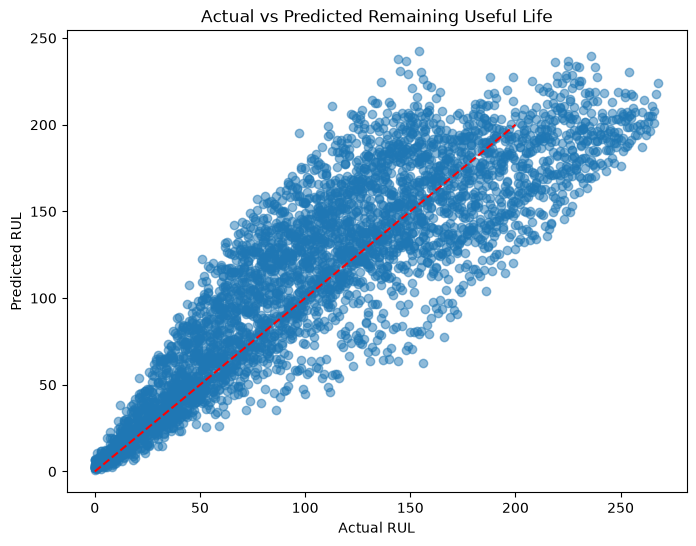

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, predictions, alpha=0.5)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted Remaining Useful Life")

plt.plot(
    [0, 200],
    [0, 200],
    color="red",
    linestyle="--"
)

plt.show()

In [24]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

      Feature  Importance
0       Cycle    0.534431
10  Sensor_11    0.143426
9    Sensor_9    0.045989
6    Sensor_4    0.031396
13  Sensor_14    0.029747
11  Sensor_12    0.028019
7    Sensor_7    0.023924
14  Sensor_15    0.023191
17  Sensor_21    0.021246
5    Sensor_3    0.020219
4    Sensor_2    0.018767
1   Setting_1    0.016362
16  Sensor_20    0.016105
8    Sensor_8    0.015743
12  Sensor_13    0.014196
2   Setting_2    0.010419
15  Sensor_17    0.006821
3   Setting_3    0.000000


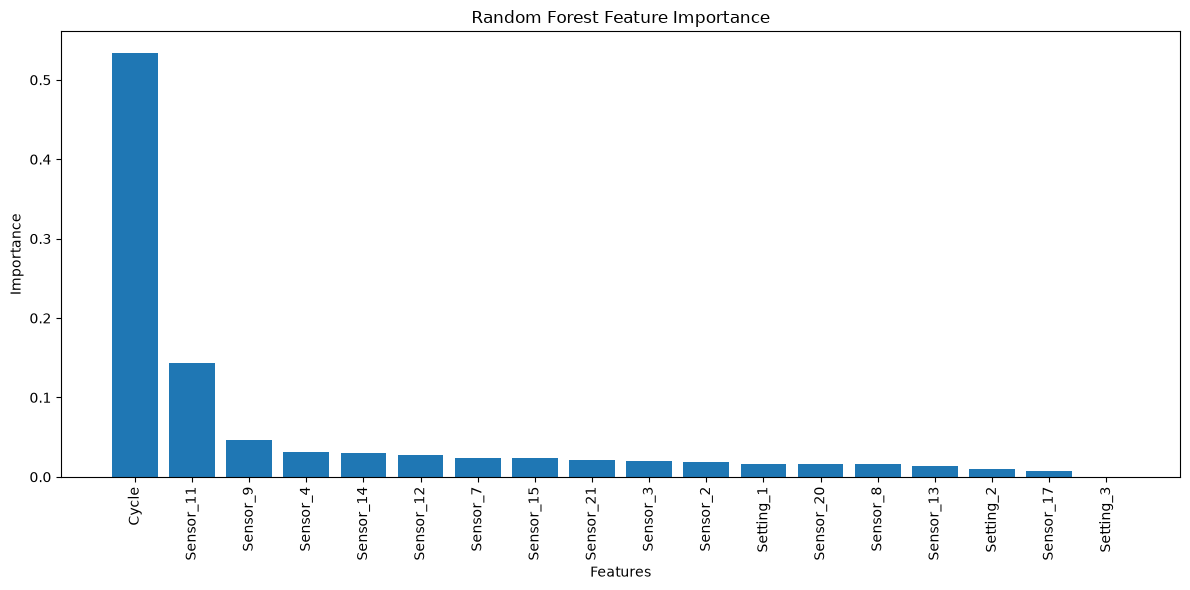

In [25]:
plt.figure(figsize=(12, 6))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [26]:
results = pd.DataFrame({
    "Actual_RUL": y_val,
    "Predicted_RUL": predictions
})

results["Error"] = (
    results["Actual_RUL"] - results["Predicted_RUL"]
)

print(results.head(10))

   Actual_RUL  Predicted_RUL  Error
0         191         215.66 -24.66
1         190         211.31 -21.31
2         189         202.23 -13.23
3         188         227.69 -39.69
4         187         217.55 -30.55
5         186         210.90 -24.90
6         185         203.75 -18.75
7         184         212.07 -28.07
8         183         208.95 -25.95
9         182         204.76 -22.76


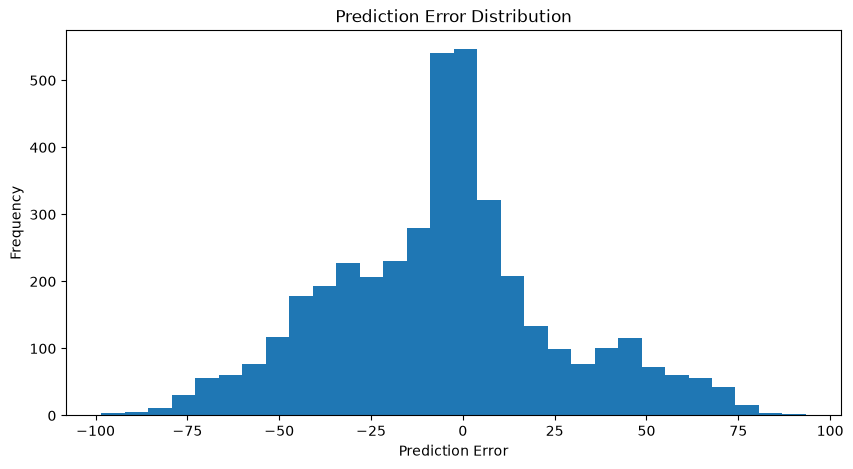

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(results["Error"], bins=30)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution")

plt.show()

In [30]:
! pip install xgboost


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [32]:
xgb_predictions = xgb_model.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)

xgb_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_predictions)
)

xgb_r2 = r2_score(y_val, xgb_predictions)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 23.578392028808594
XGBoost RMSE: 31.115467250968507
XGBoost R2: 0.7753750681877136


In [33]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [mae, xgb_mae],
    "RMSE": [rmse, xgb_rmse],
    "R2 Score": [r2, xgb_r2]
})

print(comparison)

           Model        MAE       RMSE  R2 Score
0  Random Forest  24.045000  31.748280  0.766145
1        XGBoost  23.578392  31.115467  0.775375


In [34]:
importance = xgb_model.feature_importances_

xgb_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print(xgb_importance)

      Feature  Importance
0       Cycle    0.483435
10  Sensor_11    0.135542
6    Sensor_4    0.077014
11  Sensor_12    0.049617
9    Sensor_9    0.039917
7    Sensor_7    0.037410
14  Sensor_15    0.026912
16  Sensor_20    0.020969
13  Sensor_14    0.020731
8    Sensor_8    0.020374
17  Sensor_21    0.018034
4    Sensor_2    0.015921
12  Sensor_13    0.014098
5    Sensor_3    0.012136
15  Sensor_17    0.011966
2   Setting_2    0.008320
1   Setting_1    0.007605
3   Setting_3    0.000000


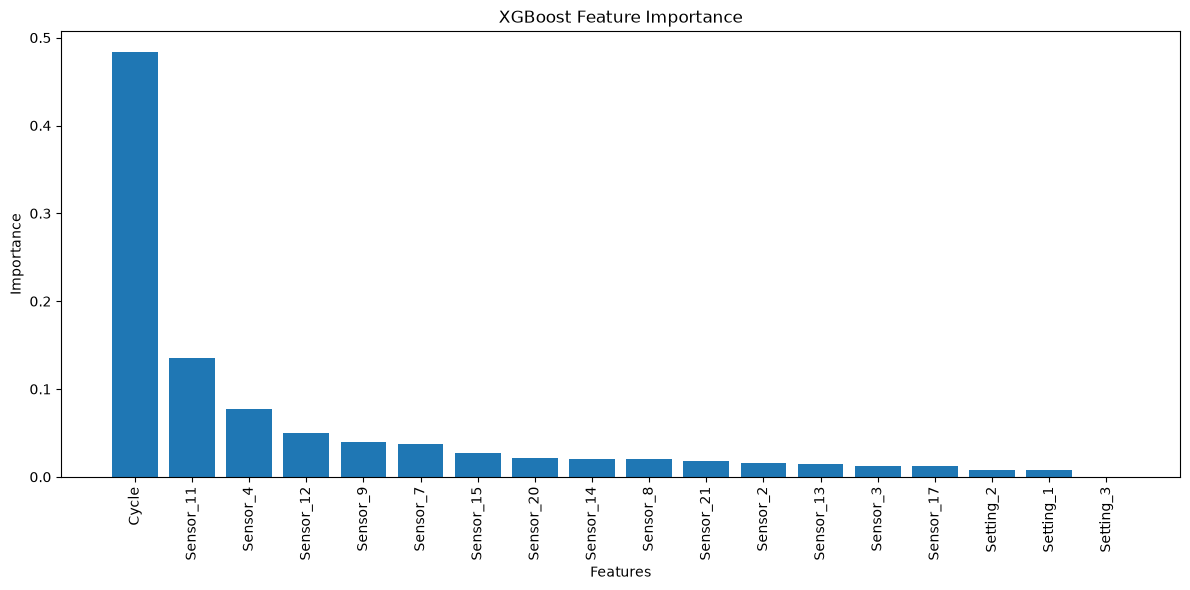

In [35]:
plt.figure(figsize=(12, 6))

plt.bar(
    xgb_importance["Feature"],
    xgb_importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("XGBoost Feature Importance")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [44]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from xgboost import XGBRegressor

import numpy as np

In [45]:
param_grid = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6, 8],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3],
    "reg_lambda": [1, 5, 10]
}

In [46]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

group_kfold = GroupKFold(n_splits=5)

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [47]:
train_groups = train.loc[X_train.index, "Engine_ID"]

random_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator,

In [49]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-random_search.best_score_)

Best Parameters:
{'subsample': 0.8, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.7}

Best Cross-Validation MAE:
27.67302894592285


In [50]:
best_xgb_model = random_search.best_estimator_

In [51]:
tuned_predictions = best_xgb_model.predict(X_val)

In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tuned_mae = mean_absolute_error(y_val, tuned_predictions)

tuned_rmse = np.sqrt(
    mean_squared_error(y_val, tuned_predictions)
)

tuned_r2 = r2_score(y_val, tuned_predictions)

print("Tuned XGBoost MAE:", tuned_mae)
print("Tuned XGBoost RMSE:", tuned_rmse)
print("Tuned XGBoost R2:", tuned_r2)

Tuned XGBoost MAE: 22.408836364746094
Tuned XGBoost RMSE: 29.30142777124681
Tuned XGBoost R2: 0.8008029460906982


In [53]:
comparison = pd.DataFrame({
    "Model": ["Original XGBoost", "Tuned XGBoost"],
    "MAE": [23.578392, tuned_mae],
    "RMSE": [31.115467, tuned_rmse],
    "R2 Score": [0.775375, tuned_r2]
})

print(comparison)

              Model        MAE       RMSE  R2 Score
0  Original XGBoost  23.578392  31.115467  0.775375
1     Tuned XGBoost  22.408836  29.301428  0.800803


In [54]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Original XGBoost",
        "Tuned XGBoost",
        "ANN"
    ],
    "MAE": [
        24.045,
        23.578392,
        tuned_mae,
        23.793375
    ],
    "RMSE": [
        31.748280,
        31.115467,
        tuned_rmse,
        30.586844
    ],
    "R2 Score": [
        0.766145,
        0.775375,
        tuned_r2,
        0.782943
    ]
})

print(comparison.sort_values("MAE"))

              Model        MAE       RMSE  R2 Score
2     Tuned XGBoost  22.408836  29.301428  0.800803
1  Original XGBoost  23.578392  31.115467  0.775375
3               ANN  23.793375  30.586844  0.782943
0     Random Forest  24.045000  31.748280  0.766145


In [36]:
! pip install tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp314-cp314-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.85.1-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached h5py-3.15.1-cp314-cp314-win_amd64.whl.metadata (3.1 kB)
  Using cached ml_dtypes-0.6.0-cp314-cp314-win_amd64.whl.metadata (8.8 kB)
 


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

from sklearn.preprocessing import StandardScaler

In [38]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)

Training shape: (16561, 18)
Validation shape: (4070, 18)


In [39]:
ann_model = Sequential()

ann_model.add(
    Dense(128, activation="relu",
          input_shape=(X_train_scaled.shape[1],))
)

ann_model.add(Dropout(0.2))

ann_model.add(
    Dense(64, activation="relu")
)

ann_model.add(
    Dense(32, activation="relu")
)

ann_model.add(
    Dense(1, activation="linear")
)

ann_model.summary()

c:\Users\Shib\AeroPredict-AI\venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
ann_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [41]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=64
)

Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4642.9219 - mae: 48.8889 - val_loss: 939.9344 - val_mae: 23.8745
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1659.1218 - mae: 29.3519 - val_loss: 898.4180 - val_mae: 23.1358
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1565.6851 - mae: 28.1318 - val_loss: 904.3096 - val_mae: 23.1513
Epoch 4/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1521.4993 - mae: 27.5491 - val_loss: 878.3370 - val_mae: 22.7875
Epoch 5/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1498.4099 - mae: 27.2022 - val_loss: 889.2243 - val_mae: 22.8683
Epoch 6/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1488.5868 - mae: 27.0515 - val_loss: 882.5822 - val_mae: 22.7721
Epoch 7/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1472.7737 - mae: 26.8769 - val_loss: 880.4193 - val_mae: 22.8069
Epoch 8/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1464.0658 - mae: 26.7094 - val_loss: 895.5736 - val_mae: 23.0656


In [42]:
ann_predictions = ann_model.predict(X_val_scaled).flatten()

ann_mae = mean_absolute_error(y_val, ann_predictions)

ann_rmse = np.sqrt(
    mean_squared_error(y_val, ann_predictions)
)

ann_r2 = r2_score(y_val, ann_predictions)

print("ANN MAE:", ann_mae)
print("ANN RMSE:", ann_rmse)
print("ANN R2:", ann_r2)

128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step
ANN MAE: 23.79337501525879
ANN RMSE: 30.586844454943982
ANN R2: 0.7829425930976868


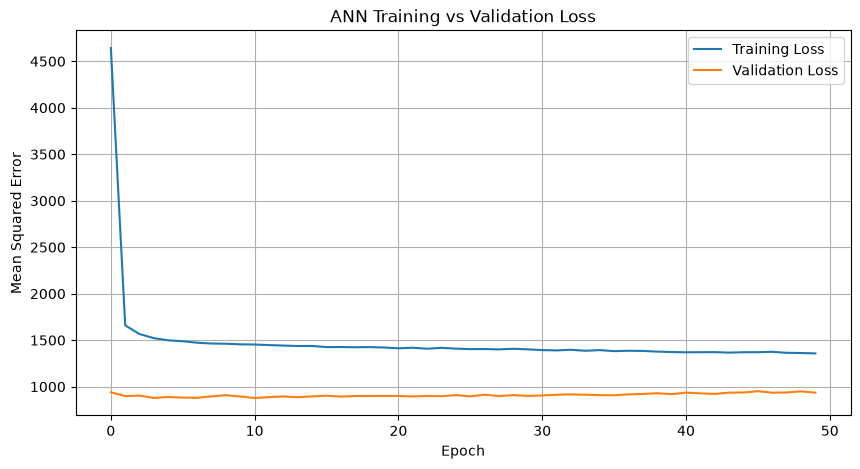

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("ANN Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [55]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd

In [56]:
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.22.0-rc0


In [57]:
sequence_length = 30

print("Sequence Length:", sequence_length)
print("Number of Input Features:", len(feature_columns))

Sequence Length: 30
Number of Input Features: 18


In [58]:
def create_sequences(data, sequence_length, feature_columns):

    X_sequences = []
    y_sequences = []

    # Process each engine separately
    for engine_id in data["Engine_ID"].unique():

        # Select one engine
        engine_data = data[data["Engine_ID"] == engine_id]

        # Sort by cycle
        engine_data = engine_data.sort_values("Cycle")

        # Extract features
        features = engine_data[feature_columns].values

        # Extract RUL values
        targets = engine_data["RUL"].values

        # Create sequences
        for i in range(len(engine_data) - sequence_length + 1):

            X_sequences.append(
                features[i:i + sequence_length]
            )

            y_sequences.append(
                targets[i + sequence_length - 1]
            )

    return np.array(X_sequences), np.array(y_sequences)

In [59]:
X_train_lstm, y_train_lstm = create_sequences(
    train.loc[X_train.index].assign(RUL=y_train),
    sequence_length,
    feature_columns
)

In [60]:
train_engine_ids = train.loc[X_train.index, "Engine_ID"].unique()

train_lstm_data = train[
    train["Engine_ID"].isin(train_engine_ids)
].copy()

X_train_lstm, y_train_lstm = create_sequences(
    train_lstm_data,
    sequence_length,
    feature_columns
)

In [61]:
val_engine_ids = train.loc[X_val.index, "Engine_ID"].unique()

val_lstm_data = train[
    train["Engine_ID"].isin(val_engine_ids)
].copy()

X_val_lstm, y_val_lstm = create_sequences(
    val_lstm_data,
    sequence_length,
    feature_columns
)

In [62]:
print("Training sequences:", X_train_lstm.shape)
print("Training targets:", y_train_lstm.shape)

print("Validation sequences:", X_val_lstm.shape)
print("Validation targets:", y_val_lstm.shape)

Training sequences: (14241, 30, 18)
Training targets: (14241,)
Validation sequences: (3490, 30, 18)
Validation targets: (3490,)


In [63]:
from sklearn.preprocessing import StandardScaler

# Create scaler
lstm_scaler = StandardScaler()

# Fit only on training features
lstm_scaler.fit(X_train)

# Get sequence dimensions
n_train, seq_len, n_features = X_train_lstm.shape
n_val = X_val_lstm.shape[0]

# Reshape 3D sequences into 2D
X_train_reshaped = X_train_lstm.reshape(-1, n_features)
X_val_reshaped = X_val_lstm.reshape(-1, n_features)

# Scale the features
X_train_scaled_lstm = lstm_scaler.transform(X_train_reshaped)
X_val_scaled_lstm = lstm_scaler.transform(X_val_reshaped)

# Convert back to 3D
X_train_scaled_lstm = X_train_scaled_lstm.reshape(
    n_train, seq_len, n_features
)

X_val_scaled_lstm = X_val_scaled_lstm.reshape(
    n_val, seq_len, n_features
)

print("Training shape:", X_train_scaled_lstm.shape)
print("Validation shape:", X_val_scaled_lstm.shape)

Training shape: (14241, 30, 18)
Validation shape: (3490, 30, 18)


c:\Users\Shib\AeroPredict-AI\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Shib\AeroPredict-AI\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [64]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

lstm_model = Sequential([
    Input(shape=(sequence_length, len(feature_columns))),

    LSTM(64, return_sequences=True),

    Dropout(0.2),

    LSTM(32),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1, activation="linear")
])

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,753 (135.75 KB)

 Trainable params: 34,753 (135.75 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [66]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train_scaled_lstm,
    y_train_lstm,
    validation_data=(
        X_val_scaled_lstm,
        y_val_lstm
    ),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 8582.1055 - mae: 71.2135 - val_loss: 3476.9270 - val_mae: 41.4035
Epoch 2/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 2302.6968 - mae: 31.1746 - val_loss: 867.6073 - val_mae: 21.2967
Epoch 3/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 1143.3455 - mae: 21.9530 - val_loss: 655.8429 - val_mae: 18.4528
Epoch 4/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 880.5203 - mae: 19.3757 - val_loss: 673.4777 - val_mae: 18.6814
Epoch 5/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 768.9453 - mae: 18.2199 - val_loss: 745.4940 - val_mae: 19.3605
Epoch 6/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 667.5203 - mae: 16.9384 - val_loss: 846.8717 - val_mae: 20.3444
Epoch 7/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 539.0215 - mae: 15.3579 - val_loss: 909.0590 - val_mae: 20.5638
Epoch 8/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 474.6519 - mae: 14.4440 - val_loss: 1000.8901 - val_mae: 22.

In [67]:
lstm_predictions = lstm_model.predict(
    X_val_scaled_lstm
).flatten()

lstm_mae = mean_absolute_error(
    y_val_lstm,
    lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(y_val_lstm, lstm_predictions)
)

lstm_r2 = r2_score(
    y_val_lstm,
    lstm_predictions
)

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)
print("LSTM R2:", lstm_r2)

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
LSTM MAE: 18.452810287475586
LSTM RMSE: 25.609433391101827
LSTM R2: 0.806686282157898


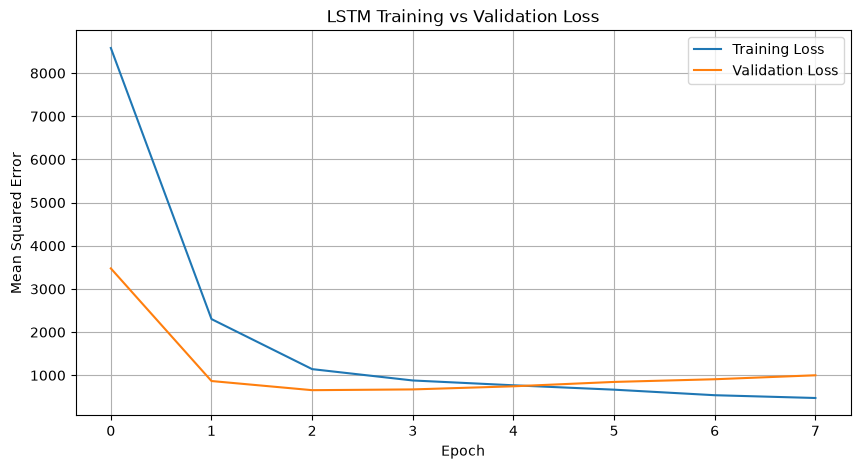

In [69]:
plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [70]:
from tensorflow.keras.layers import GRU

In [71]:
gru_model = Sequential([
    Input(shape=(sequence_length, len(feature_columns))),

    GRU(64, return_sequences=True),

    Dropout(0.2),

    GRU(32),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1, activation="linear")
])

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 30, 64)         │        16,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,625 (104.00 KB)

 Trainable params: 26,625 (104.00 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [73]:
gru_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

gru_history = gru_model.fit(
    X_train_scaled_lstm,
    y_train_lstm,
    validation_data=(
        X_val_scaled_lstm,
        y_val_lstm
    ),
    epochs=50,
    batch_size=64,
    callbacks=[gru_early_stopping],
    verbose=1
)

Epoch 1/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 7937.2295 - mae: 69.0436 - val_loss: 3178.5840 - val_mae: 42.0170
Epoch 2/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 2431.7227 - mae: 36.2820 - val_loss: 1191.3892 - val_mae: 27.1066
Epoch 3/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1653.6790 - mae: 30.0550 - val_loss: 828.4147 - val_mae: 22.0785
Epoch 4/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1436.3021 - mae: 27.3035 - val_loss: 777.2963 - val_mae: 21.6365
Epoch 5/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1300.0942 - mae: 25.2410 - val_loss: 719.5673 - val_mae: 20.4168
Epoch 6/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1231.7651 - mae: 24.3245 - val_loss: 722.7175 - val_mae: 20.7079
Epoch 7/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1179.7943 - mae: 23.9869 - val_loss: 670.3968 - val_mae: 19.4643
Epoch 8/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1114.9088 - mae: 23.1338 - val_loss: 564.2713 - val_mae

In [74]:
gru_predictions = gru_model.predict(
    X_val_scaled_lstm
).flatten()

gru_mae = mean_absolute_error(
    y_val_lstm, gru_predictions
)

gru_rmse = np.sqrt(
    mean_squared_error(y_val_lstm, gru_predictions)
)

gru_r2 = r2_score(
    y_val_lstm, gru_predictions
)

print("GRU MAE:", gru_mae)
print("GRU RMSE:", gru_rmse)
print("GRU R2:", gru_r2)

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
GRU MAE: 17.4576416015625
GRU RMSE: 23.754396694184585
GRU R2: 0.8336775898933411


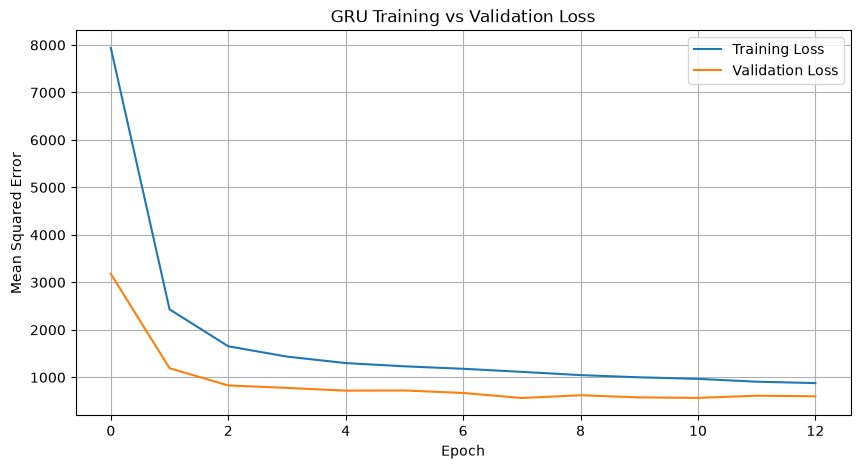

In [75]:
plt.figure(figsize=(10, 5))

plt.plot(
    gru_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    gru_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("GRU Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [76]:
# Load test dataset
test_data = pd.read_csv(
    "../dataset/raw/test_FD001.txt",
    sep=r"\s+",
    header=None
)

# Assign column names
test_data.columns = columns

# Load actual RUL values
actual_rul = pd.read_csv(
    "../dataset/raw/RUL_FD001.txt",
    sep=r"\s+",
    header=None
)

actual_rul.columns = ["RUL"]

# Display information
print("Test data shape:", test_data.shape)
print("Actual RUL shape:", actual_rul.shape)

display(test_data.head())
display(actual_rul.head())

Test data shape: (13096, 26)
Actual RUL shape: (100, 1)


,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,RUL
0,112
1,98
2,69
3,82
4,91


In [77]:
# Sort test data by engine and cycle
test_data = test_data.sort_values(
    ["Engine_ID", "Cycle"]
)

# Get the last recorded cycle of each engine
test_last = test_data.groupby(
    "Engine_ID"
).tail(1).sort_values("Engine_ID")

# Extract selected features
X_test = test_last[feature_columns]

print("Final test observations:", X_test.shape)
print("Number of test engines:", test_last["Engine_ID"].nunique())

display(test_last.head())

Final test observations: (100, 18)
Number of test engines: 100


,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,521.79,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,521.74,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,520.83,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,521.88,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,521.00,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117


In [78]:
test_engine_lengths = test_data.groupby(
    "Engine_ID"
)["Cycle"].count()

print("Minimum cycles:", test_engine_lengths.min())
print("Maximum cycles:", test_engine_lengths.max())
print("Engines with fewer than 30 cycles:",
      (test_engine_lengths < sequence_length).sum())

Minimum cycles: 31
Maximum cycles: 303
Engines with fewer than 30 cycles: 0


In [79]:
# Random Forest predictions
rf_test_predictions = model.predict(X_test)

# Tuned XGBoost predictions
xgb_test_predictions = best_xgb_model.predict(X_test)

# ANN predictions
X_test_scaled = scaler.transform(X_test)

ann_test_predictions = ann_model.predict(
    X_test_scaled
).flatten()

# Actual RUL values
y_test = actual_rul["RUL"].values

print("Number of actual RUL values:", len(y_test))
print("Random Forest predictions:", len(rf_test_predictions))
print("XGBoost predictions:", len(xgb_test_predictions))
print("ANN predictions:", len(ann_test_predictions))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Number of actual RUL values: 100
Random Forest predictions: 100
XGBoost predictions: 100
ANN predictions: 100


In [80]:
def evaluate_model(model_name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


test_results = []

test_results.append(
    evaluate_model("Random Forest", y_test, rf_test_predictions)
)

test_results.append(
    evaluate_model("Tuned XGBoost", y_test, xgb_test_predictions)
)

test_results.append(
    evaluate_model("ANN", y_test, ann_test_predictions)
)

test_comparison = pd.DataFrame(test_results)

display(test_comparison)

,Model,MAE,RMSE,R2 Score
0,Random Forest,20.370900,27.415043,0.564770
1,Tuned XGBoost,18.067682,24.918979,0.640416
2,ANN,19.130451,25.608765,0.620233


In [81]:
# Sort test data
test_data = test_data.sort_values(
    ["Engine_ID", "Cycle"]
)

# Store sequences
test_sequences = []

# Process each engine separately
for engine_id in sorted(test_data["Engine_ID"].unique()):

    engine_data = test_data[
        test_data["Engine_ID"] == engine_id
    ]

    # Select the last 30 cycles
    last_30_cycles = engine_data.tail(sequence_length)

    # Extract selected features
    sequence = last_30_cycles[feature_columns].values

    test_sequences.append(sequence)

# Convert to NumPy array
X_test_lstm = np.array(test_sequences)

print("Test LSTM sequence shape:", X_test_lstm.shape)

Test LSTM sequence shape: (100, 30, 18)


In [82]:
# Get dimensions
n_test, seq_len, n_features = X_test_lstm.shape

# Reshape into 2D
X_test_reshaped = X_test_lstm.reshape(
    -1, n_features
)

# Apply training scaler
X_test_scaled_lstm = lstm_scaler.transform(
    X_test_reshaped
)

# Convert back to 3D
X_test_scaled_lstm = X_test_scaled_lstm.reshape(
    n_test, seq_len, n_features
)

print("Scaled test shape:", X_test_scaled_lstm.shape)

Scaled test shape: (100, 30, 18)


c:\Users\Shib\AeroPredict-AI\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [83]:
# LSTM predictions
lstm_test_predictions = lstm_model.predict(
    X_test_scaled_lstm
).flatten()

# GRU predictions
gru_test_predictions = gru_model.predict(
    X_test_scaled_lstm
).flatten()

print("LSTM predictions:", len(lstm_test_predictions))
print("GRU predictions:", len(gru_test_predictions))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
LSTM predictions: 100
GRU predictions: 100


In [84]:
test_results = []

test_results.append(
    evaluate_model("Random Forest", y_test, rf_test_predictions)
)

test_results.append(
    evaluate_model("Tuned XGBoost", y_test, xgb_test_predictions)
)

test_results.append(
    evaluate_model("ANN", y_test, ann_test_predictions)
)

test_results.append(
    evaluate_model("LSTM", y_test, lstm_test_predictions)
)

test_results.append(
    evaluate_model("GRU", y_test, gru_test_predictions)
)

final_comparison = pd.DataFrame(test_results)

final_comparison = final_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

display(final_comparison)

,Model,MAE,RMSE,R2 Score
0,LSTM,16.432417,23.576680,0.678111
1,Tuned XGBoost,18.067682,24.918979,0.640416
2,ANN,19.130451,25.608765,0.620233
3,GRU,19.210943,27.106121,0.574524
4,Random Forest,20.370900,27.415043,0.564770


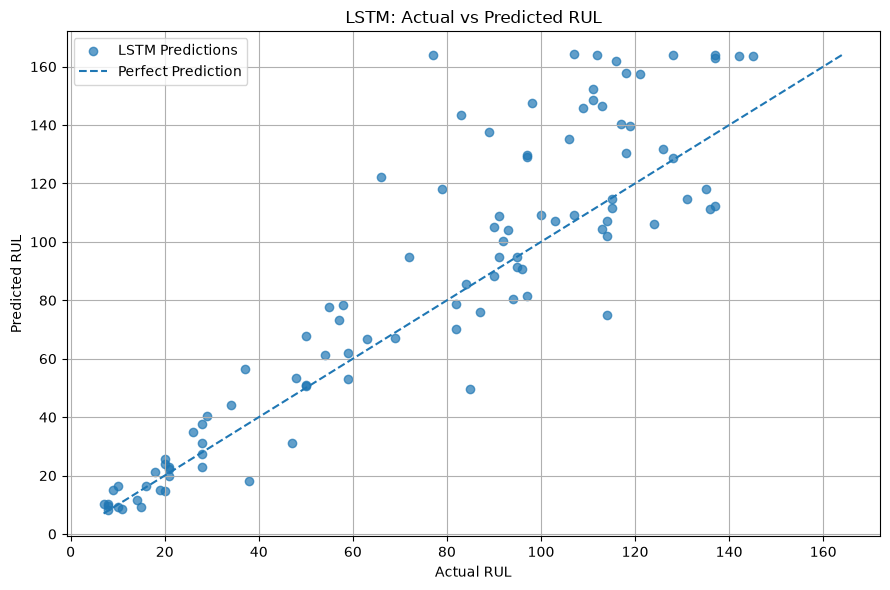

In [85]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    lstm_test_predictions,
    alpha=0.7,
    label="LSTM Predictions"
)

# Perfect prediction reference line
minimum = min(y_test.min(), lstm_test_predictions.min())
maximum = max(y_test.max(), lstm_test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("LSTM: Actual vs Predicted RUL")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [86]:
! pip install shap

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]




[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [93]:
def lstm_shap_predict(data):

    # Reshape flattened data into LSTM input format
    sequences = data.reshape(
        -1,
        sequence_length,
        len(feature_columns)
    )

    # Generate LSTM predictions
    predictions = lstm_model.predict(
        sequences,
        verbose=0
    ).flatten()

    return predictions

In [95]:
# Select background samples
rng = np.random.default_rng(42)

background_indices = rng.choice(
    len(X_train_scaled_lstm),
    size=20,
    replace=False
)

background_data = X_train_scaled_lstm[
    background_indices
]

# Select two test engines
explain_data = X_test_scaled_lstm[:2]

# Flatten sequences for SHAP
background_flat = background_data.reshape(
    len(background_data), -1
)

explain_flat = explain_data.reshape(
    len(explain_data), -1
)

print("Background shape:", background_flat.shape)
print("Explanation shape:", explain_flat.shape)

Background shape: (20, 540)
Explanation shape: (2, 540)


In [96]:
explainer = shap.KernelExplainer(
    lstm_shap_predict,
    background_flat
)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [98]:
shap_values = explainer.shap_values(
    explain_flat,
    nsamples=100
)

print("SHAP values calculated!")


  0%|          | 0/2 [00:00<?, ?it/s]

SHAP values calculated!


In [99]:
# Convert SHAP values to NumPy array
shap_array = np.array(shap_values)

# Handle different SHAP output formats
if shap_array.ndim == 3:
    shap_array = shap_array[:, :, 0]

# Calculate mean absolute SHAP importance
shap_importance = np.mean(
    np.abs(shap_array),
    axis=0
)

# Reshape into cycles and features
shap_importance = shap_importance.reshape(
    sequence_length,
    len(feature_columns)
)

# Combine importance across 30 cycles
sensor_importance = shap_importance.mean(axis=0)

# Create importance table
shap_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": sensor_importance
})

shap_df = shap_df.sort_values(
    "Importance",
    ascending=False
)

display(shap_df)

,Feature,Importance
10,Sensor_11,0.792993
0,Cycle,0.757087
6,Sensor_4,0.655371
4,Sensor_2,0.541948
1,Setting_1,0.266010
15,Sensor_17,0.200511
2,Setting_2,0.176746
12,Sensor_13,0.104516
9,Sensor_9,0.090628
13,Sensor_14,0.087571


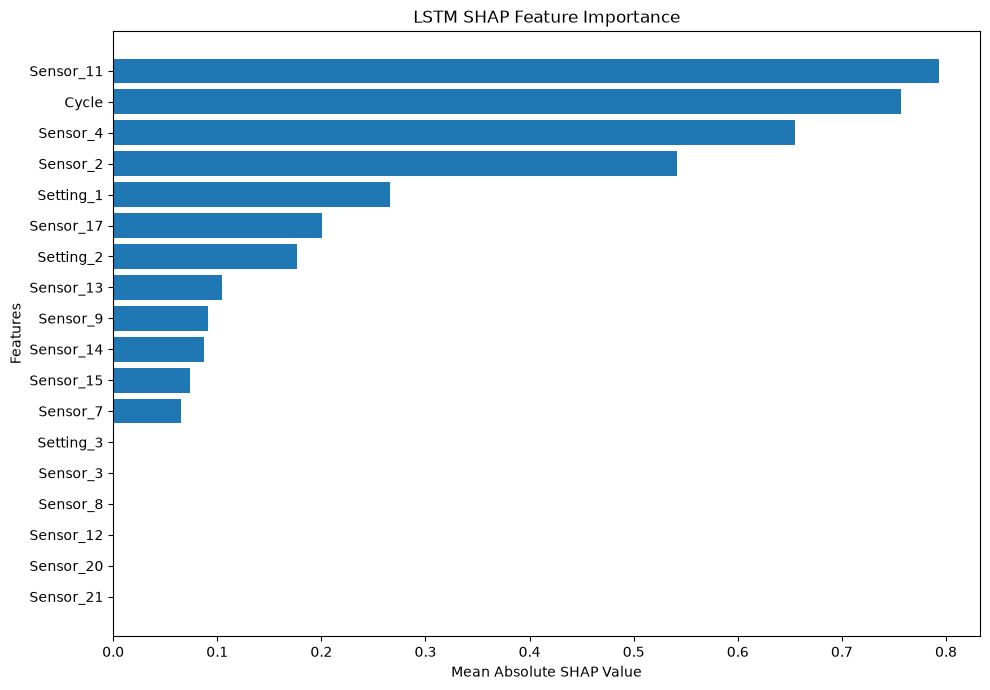

In [100]:
plt.figure(figsize=(10, 7))

plt.barh(
    shap_df["Feature"],
    shap_df["Importance"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("LSTM SHAP Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [101]:
import os
import joblib

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save trained LSTM model
lstm_model.save("../models/aeropredict_lstm.keras")

# Save scaler and feature information
model_config = {
    "scaler": lstm_scaler,
    "feature_columns": feature_columns,
    "sequence_length": sequence_length
}

joblib.dump(
    model_config,
    "../models/aeropredict_config.pkl"
)

print("LSTM model saved successfully!")
print("Model configuration saved successfully!")

LSTM model saved successfully!
Model configuration saved successfully!


In [102]:
import os

os.makedirs("../reports", exist_ok=True)

shap_df.to_csv(
    "../reports/shap_feature_importance.csv",
    index=False
)

final_comparison.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("SHAP results and model comparison saved!")

SHAP results and model comparison saved!
